In [2]:
import re
import numpy as np
import pandas as pd

# 1. Load the dataset (use the exact file name in your directory)
file_path = "clinvar_download_20260928_041734_2.xlsx"
df = pd.read_excel("C:\\Users\\Charita\\Downloads\\clinvar_download_20260928_041734.xlsx")

print(f"Original Dataset Shape: {df.shape}")

# 2. Filter for Epilepsy-related conditions
epilepsy_keywords = "epilep|seizure|spasm|dee|smei|encephalopathy"
df_epilepsy = df[
    df["Condition(s)"].astype(str).str.contains(epilepsy_keywords, case=False, na=False)
].copy()

# 3. Target Labeling using 'Germline classification'
# 1 = Pathogenic / Likely Pathogenic (Disease causing)
# 0 = Likely Pathogenic / Lower severity class (or Benign if present)
df_epilepsy["class_label"] = df_epilepsy["Germline classification"].map(
    {
        "Pathogenic": 1,
        "Pathogenic/Likely pathogenic": 1,
        "Likely pathogenic": 0,
    }
)

# Filter out rows with missing target labels
df_ml = df_epilepsy.dropna(subset=["class_label"]).copy()
df_ml["class_label"] = df_ml["class_label"].astype(int)

# 4. Extract DNA & Variant Information from 'Canonical SPDI' and 'Name'
def parse_spdi(spdi):
    if pd.isna(spdi) or not isinstance(spdi, str):
        return pd.Series([np.nan, np.nan, np.nan])
    parts = spdi.split(":")
    if len(parts) == 4:
        try:
            return pd.Series([int(parts[1]), parts[2], parts[3]])
        except:
            return pd.Series([np.nan, np.nan, np.nan])
    return pd.Series([np.nan, np.nan, np.nan])

spdi_parsed = df_ml["Canonical SPDI"].apply(parse_spdi)
df_ml["Genomic_Pos"] = spdi_parsed[0]
df_ml["Ref_Allele"] = spdi_parsed[1]
df_ml["Alt_Allele"] = spdi_parsed[2]

# 5. Select and order output features
features_to_keep = [
    "VariationID",
    "Gene(s)",
    "Name",
    "Protein change",
    "Condition(s)",
    "Variant type",
    "Molecular consequence",
    "Genomic_Pos",
    "Ref_Allele",
    "Alt_Allele",
    "GRCh38Location",
    "Germline classification",
    "class_label",
]

available_features = [col for col in features_to_keep if col in df_ml.columns]
df_processed = df_ml[available_features]

# 6. Save the processed dataset
output_file = "processed_epilepsy_variants.csv"
df_processed.to_csv(output_file, index=False)

print("\n--- Processing Summary ---")
print(f"Processed Dataset Shape: {df_processed.shape}")
print("\nTarget Label Distribution:")
print(df_processed["class_label"].value_counts().rename({1: "Pathogenic (1)", 0: "Likely Pathogenic (0)"}))
print(f"\nProcessed file saved to: {output_file}")

Original Dataset Shape: (2322, 24)

--- Processing Summary ---
Processed Dataset Shape: (1791, 13)

Target Label Distribution:
class_label
Pathogenic (1)           1359
Likely Pathogenic (0)     432
Name: count, dtype: int64

Processed file saved to: processed_epilepsy_variants.csv


In [3]:
import os
print("Your file is saved at:")
print(os.path.abspath("processed_epilepsy_variants.csv"))

Your file is saved at:
C:\Users\Charita\Desktop\processed_epilepsy_variants.csv


In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score

# 1. Load dataset
df = pd.read_csv('processed_epilepsy_variants.csv')

# 2. Feature Engineering
df['ref_len'] = df['Ref_Allele'].fillna('').apply(len)
df['alt_len'] = df['Alt_Allele'].fillna('').apply(len)
df['indel_size'] = df['alt_len'] - df['ref_len']

def parse_consequence(mc):
    if pd.isna(mc): return 'unknown'
    mc = str(mc).lower()
    if 'missense' in mc: return 'missense'
    if 'frameshift' in mc: return 'frameshift'
    if 'nonsense' in mc: return 'nonsense'
    if 'splice' in mc: return 'splice'
    if 'synonymous' in mc: return 'synonymous'
    return 'other'

df['consequence_category'] = df['Molecular consequence'].apply(parse_consequence)

# 3. Categorical & Numerical Feature Assembly
X_cat = pd.get_dummies(df[['Variant type', 'consequence_category', 'Ref_Allele', 'Alt_Allele']], drop_first=True)
X_num = df[['ref_len', 'alt_len', 'indel_size']]
X = pd.concat([X_num, X_cat], axis=1)
y = df['class_label']

# 4. Train/Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Train Gradient Boosting Model
model = GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42)
model.fit(X_train, y_train)

# 6. Predict Probabilities & Find Optimal Threshold
y_probs = model.predict_proba(X_test)[:, 1]

best_thresh = 0.5
best_macro_f1 = 0
for thresh in np.arange(0.3, 0.85, 0.02):
    preds = (y_probs >= thresh).astype(int)
    score = f1_score(y_test, preds, average='macro')
    if score > best_macro_f1:
        best_macro_f1 = score
        best_thresh = thresh

# 7. Final Tuned Predictions
y_pred_tuned = (y_probs >= best_thresh).astype(int)

print(f"--- Optimized Model Performance ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_probs):.4f}")
print(f"Optimal Decision Threshold: {best_thresh:.2f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=['Likely Pathogenic (0)', 'Pathogenic (1)']))

--- Optimized Model Performance ---
ROC-AUC Score: 0.7491
Optimal Decision Threshold: 0.64

Classification Report:
                       precision    recall  f1-score   support

Likely Pathogenic (0)       0.52      0.59      0.55        87
       Pathogenic (1)       0.86      0.83      0.84       272

             accuracy                           0.77       359
            macro avg       0.69      0.71      0.70       359
         weighted avg       0.78      0.77      0.77       359



In [5]:
# Extract top 10 important features
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 Most Predictive Features:")
print(importances.head(10))

Top 10 Most Predictive Features:
consequence_category_missense             0.180528
consequence_category_nonsense             0.109494
ref_len                                   0.052809
indel_size                                0.050899
alt_len                                   0.041920
consequence_category_splice               0.036439
Ref_Allele_T                              0.035657
Alt_Allele_T                              0.033844
Variant type_single nucleotide variant    0.033685
Alt_Allele_C                              0.032982
dtype: float64


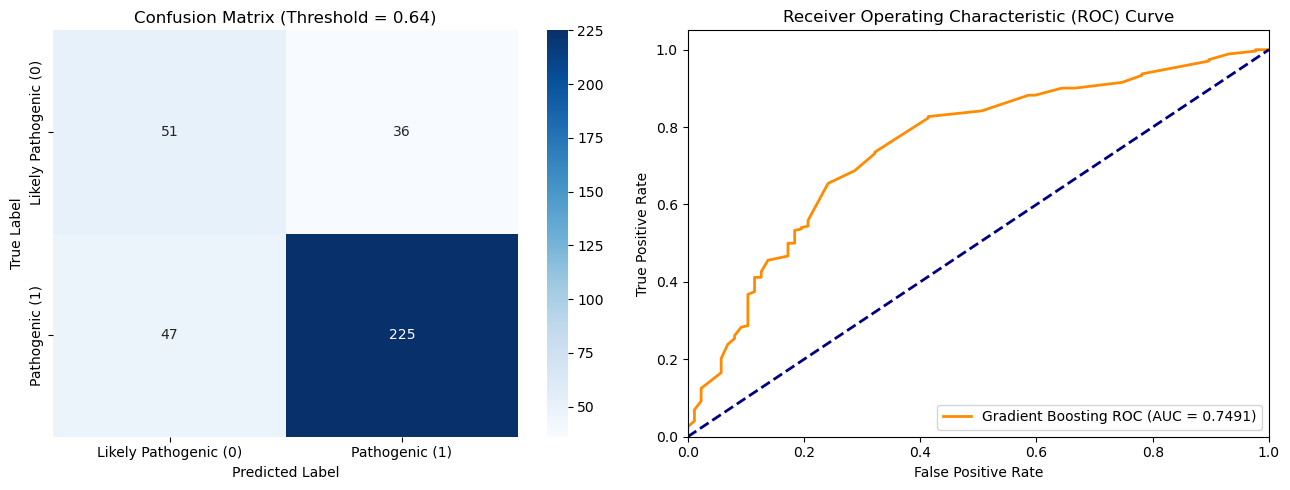

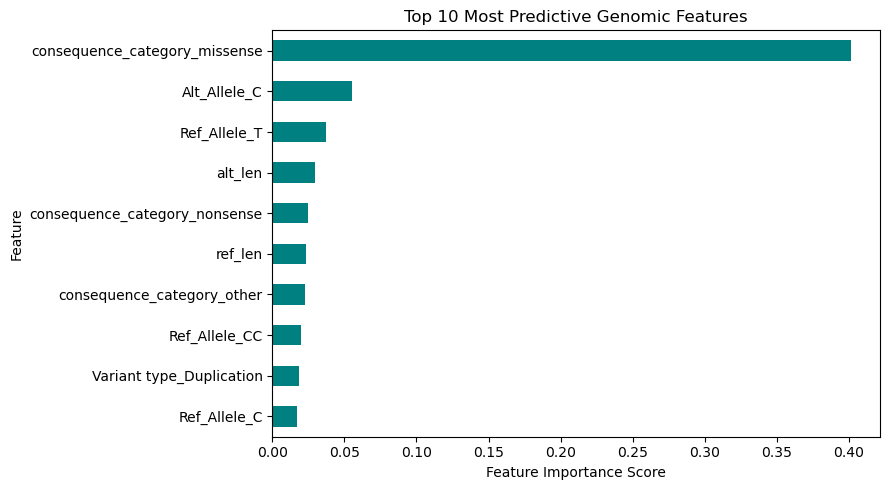

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import auc, confusion_matrix, roc_curve

# 1. Plot Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["Likely Pathogenic (0)", "Pathogenic (1)"],
    yticklabels=["Likely Pathogenic (0)", "Pathogenic (1)"],
)
axes[0].set_title("Confusion Matrix (Threshold = 0.64)", fontsize=12)
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# ROC Curve Plot
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
axes[1].plot(
    fpr,
    tpr,
    color="darkorange",
    lw=2,
    label=f"Gradient Boosting ROC (AUC = {roc_auc:.4f})",
)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=12)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# 2. Top Feature Importances Bar Chart
plt.figure(figsize=(9, 5))
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(
    ascending=True
)
importances.tail(10).plot(kind="barh", color="teal")
plt.title("Top 10 Most Predictive Genomic Features", fontsize=12)
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

=== 5-Fold Cross-Validation Model Benchmarking ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.7605     0.7745  0.9654    0.8595   0.7308
      Random Forest    0.7448     0.7708  0.9448    0.8489   0.7199
  Gradient Boosting    0.7560     0.7706  0.9662    0.8572   0.7358


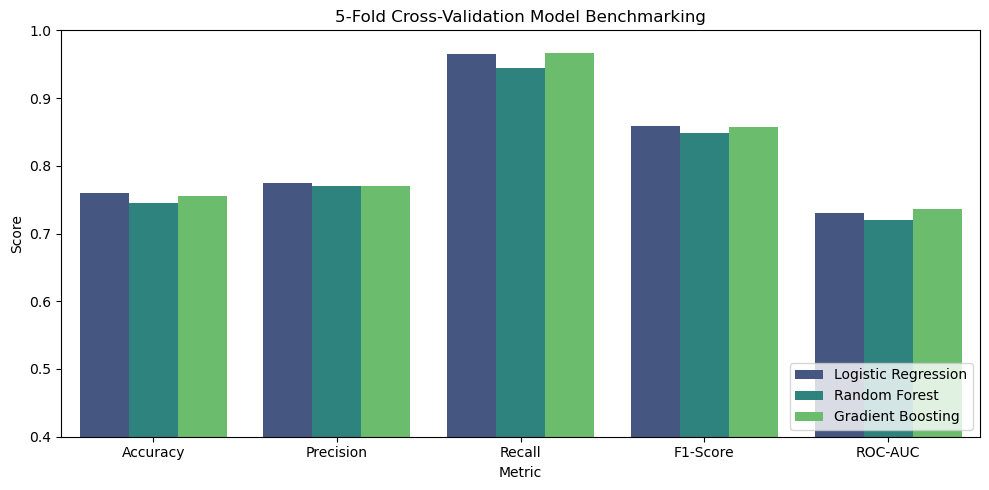

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Load dataset
df = pd.read_csv("processed_epilepsy_variants.csv")

# 2. Feature Engineering
df["ref_len"] = df["Ref_Allele"].fillna("").apply(len)
df["alt_len"] = df["Alt_Allele"].fillna("").apply(len)
df["indel_size"] = df["alt_len"] - df["ref_len"]


def parse_consequence(mc):
    if pd.isna(mc):
        return "unknown"
    mc = str(mc).lower()
    if "missense" in mc:
        return "missense"
    if "frameshift" in mc:
        return "frameshift"
    if "nonsense" in mc:
        return "nonsense"
    if "splice" in mc:
        return "splice"
    if "synonymous" in mc:
        return "synonymous"
    return "other"


df["consequence_category"] = df["Molecular consequence"].apply(
    parse_consequence
)

# 3. Features and Target Variable
X_cat = pd.get_dummies(
    df[["Variant type", "consequence_category", "Ref_Allele", "Alt_Allele"]],
    drop_first=True,
)
X_num = df[["ref_len", "alt_len", "indel_size"]]
X = pd.concat([X_num, X_cat], axis=1)
y = df["class_label"]

# 4. Define ML Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42
    ),
}

# 5. Perform 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    cv_results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    )
    results.append(
        {
            "Model": name,
            "Accuracy": cv_results["test_accuracy"].mean(),
            "Precision": cv_results["test_precision"].mean(),
            "Recall": cv_results["test_recall"].mean(),
            "F1-Score": cv_results["test_f1"].mean(),
            "ROC-AUC": cv_results["test_roc_auc"].mean(),
        }
    )

# 6. Display Benchmarking Table
results_df = pd.DataFrame(results)
print("=== 5-Fold Cross-Validation Model Benchmarking ===")
print(results_df.round(4).to_string(index=False))

# 7. Plot Performance Comparison
results_melted = results_df.melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model",
    palette="viridis",
)
plt.title("5-Fold Cross-Validation Model Benchmarking")
plt.ylim(0.4, 1.0)
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
import joblib

# 1. Save the trained model to disk
joblib.dump(model, "epilepsy_variant_model.pkl")
joblib.dump(X.columns.tolist(), "model_features.pkl")

print("Trained model successfully saved as 'epilepsy_variant_model.pkl'!")

Trained model successfully saved as 'epilepsy_variant_model.pkl'!


In [11]:
import joblib
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

# 1. Load data and process features
df = pd.read_csv("processed_epilepsy_variants.csv")

df["ref_len"] = df["Ref_Allele"].fillna("").apply(len)
df["alt_len"] = df["Alt_Allele"].fillna("").apply(len)
df["indel_size"] = df["alt_len"] - df["ref_len"]


def parse_consequence(mc):
    if pd.isna(mc):
        return "unknown"
    mc = str(mc).lower()
    if "missense" in mc:
        return "missense"
    if "frameshift" in mc:
        return "frameshift"
    if "nonsense" in mc:
        return "nonsense"
    if "splice" in mc:
        return "splice"
    if "synonymous" in mc:
        return "synonymous"
    return "other"


df["consequence_category"] = df["Molecular consequence"].apply(
    parse_consequence
)

X_cat = pd.get_dummies(
    df[["Variant type", "consequence_category", "Ref_Allele", "Alt_Allele"]],
    drop_first=True,
)
X_num = df[["ref_len", "alt_len", "indel_size"]]
X = pd.concat([X_num, X_cat], axis=1)
y = df["class_label"]

# 2. Train and Fit Model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = GradientBoostingClassifier(
    n_estimators=150, learning_rate=0.08, max_depth=4, random_state=42
)
model.fit(X_train, y_train)

# 3. Save Model and Feature Names to Disk
joblib.dump(model, "epilepsy_variant_model.pkl")
joblib.dump(X.columns.tolist(), "model_features.pkl")
print("Model trained and saved successfully!")


# 4. Define Prediction Function
def predict_new_variant(
    variant_type, consequence, ref_allele, alt_allele, threshold=0.64
):
    saved_model = joblib.load("epilepsy_variant_model.pkl")
    features = joblib.load("model_features.pkl")

    input_df = pd.DataFrame(0, index=[0], columns=features)

    ref_len = len(ref_allele)
    alt_len = len(alt_allele)
    indel_size = alt_len - ref_len

    if "ref_len" in input_df.columns:
        input_df["ref_len"] = ref_len
    if "alt_len" in input_df.columns:
        input_df["alt_len"] = alt_len
    if "indel_size" in input_df.columns:
        input_df["indel_size"] = indel_size

    vtype_col = f"Variant type_{variant_type}"
    conseq_col = f"consequence_category_{consequence}"
    ref_col = f"Ref_Allele_{ref_allele}"
    alt_col = f"Alt_Allele_{alt_allele}"

    for col in [vtype_col, conseq_col, ref_col, alt_col]:
        if col in input_df.columns:
            input_df[col] = 1

    prob = saved_model.predict_proba(input_df)[0, 1]
    prediction = (
        "Pathogenic (1)" if prob >= threshold else "Likely Pathogenic (0)"
    )

    return {
        "Pathogenicity Prediction": prediction,
        "Pathogenic Probability": f"{prob * 100:.2f}%",
    }


# 5. Run Test Prediction
sample_result = predict_new_variant(
    variant_type="single nucleotide variant",
    consequence="missense",
    ref_allele="C",
    alt_allele="T",
)

print("\n--- Real-Time Variant Prediction Output ---")
for k, v in sample_result.items():
    print(f"{k}: {v}")

Model trained and saved successfully!

--- Real-Time Variant Prediction Output ---
Pathogenicity Prediction: Pathogenic (1)
Pathogenic Probability: 71.36%


In [12]:
pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
